In [1]:
import gc
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor

RANDOM_STATE = 10
TEST_SIZE = 0.20
OUTPUT_DIR = Path("autoencoder_outputs_new")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


In [9]:
APO_FILE = "all-apo-dist.csv"

HOLO_FILES = {
    "4zlo": "4zlo-holo-merged_dist.csv",
    "4zji": "4zji-holo-merged_dist.csv",
    "4zjj": "4zjj-holo-merged_dist.csv",
}

print("Apo file:", APO_FILE)
print("Holo files:")
for system, filename in HOLO_FILES.items():
    print(f"  {system}: {filename}")

# Plot settings
LOSS_SMOOTH_WINDOW = 15
DIO_BINS = np.arange(-10.5, 10.5, 1.0)


Apo file: all-apo-dist.csv
Holo files:
  4zlo: 4zlo-holo-merged_dist.csv
  4zji: 4zji-holo-merged_dist.csv
  4zjj: 4zjj-holo-merged_dist.csv


In [3]:
def read_distance_csv(filename):
    """Read a distance-feature CSV and ensure that all columns are numeric."""
    data = pd.read_csv(filename)

    if data.empty:
        raise ValueError(f"{filename} contains no rows.")

    non_numeric = data.columns[~data.dtypes.apply(lambda dtype: np.issubdtype(dtype, np.number))]
    if len(non_numeric) > 0:
        raise TypeError(
            f"{filename} contains non-numeric columns: {list(non_numeric)}. "
            "Remove labels or metadata before reconstruction."
        )

    if data.isna().any().any():
        raise ValueError(f"{filename} contains NaN values.")

    return data


def check_feature_compatibility(reference, query, query_name):
    """Verify that the holo data have exactly the same features and order as apo."""
    if query.shape[1] != reference.shape[1]:
        raise ValueError(
            f"{query_name}: expected {reference.shape[1]} features, "
            f"but found {query.shape[1]}."
        )

    if not query.columns.equals(reference.columns):
        missing = reference.columns.difference(query.columns).tolist()
        extra = query.columns.difference(reference.columns).tolist()
        raise ValueError(
            f"{query_name}: column names/order do not match the apo dataset. "
            f"Missing examples: {missing[:5]}; extra examples: {extra[:5]}"
        )


def save_dio_histogram(dio_df, output_file, title):
    """Save the normalized DIO histogram without holding an unnecessary copy."""
    values = dio_df.to_numpy().ravel()

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.hist(
        values,
        weights=np.ones(values.size, dtype=float) / values.size,
        bins=DIO_BINS,
        alpha=0.9,
        rwidth=0.5,
    )
    ax.set_xlabel("DIO = input distance - reconstructed distance")
    ax.set_ylabel("Fraction")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(output_file, dpi=300, bbox_inches="tight")
    plt.close(fig)


def reconstruct_and_write(model, data, system_name, subset_name, histogram_cache=None):
    """Reconstruct a dataset, calculate DIO, and write CSV and PNG outputs."""
    reconstruction = model.predict(data)
    dio = pd.DataFrame(
        data.to_numpy() - reconstruction,
        index=data.index,
        columns=data.columns,
    )

    if histogram_cache is not None:
        # Retain only small histogram counts, not another full DIO matrix.
        values = dio.to_numpy().ravel()
        counts, _ = np.histogram(values, bins=DIO_BINS)
        histogram_cache[subset_name] = counts / values.size

    csv_file = OUTPUT_DIR / f"dio_{system_name}_{subset_name}.csv"
    png_file = OUTPUT_DIR / f"{system_name}_{subset_name}_dio.png"

    dio.to_csv(csv_file, index=False)
    save_dio_histogram(
        dio,
        png_file,
        title=f"{system_name}: {subset_name} DIO distribution",
    )

    summary = {
        "system": system_name,
        "subset": subset_name,
        "n_frames": len(data),
        "n_features": data.shape[1],
        "mean_DIO": float(dio.to_numpy().mean()),
        "mean_abs_DIO": float(np.abs(dio.to_numpy()).mean()),
        "rmse": float(np.sqrt(np.mean(np.square(dio.to_numpy())))),
        "csv_file": str(csv_file),
        "histogram_file": str(png_file),
    }

    del reconstruction, dio
    gc.collect()
    return summary


In [4]:
apo_df = read_distance_csv(APO_FILE)
print("Apo shape:", apo_df.shape)

apo_train, apo_test = train_test_split(
    apo_df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True,
)

print("Apo training shape:", apo_train.shape)
print("Apo held-out test shape:", apo_test.shape)


Apo shape: (5000, 41616)
Apo training shape: (4000, 41616)
Apo held-out test shape: (1000, 41616)


In [5]:
n_input = apo_df.shape[1]

n_encoder1 = max(1, n_input // 2)
n_encoder2 = max(1, n_input // 4)
n_encoder3 = max(1, n_input // 8)
n_latent   = max(1, n_input // 16)

n_decoder3 = n_encoder3
n_decoder2 = n_encoder2
n_decoder1 = n_encoder1

print(
    "Architecture:",
    n_input, "->", n_encoder1, "->", n_encoder2, "->", n_encoder3,
    "->", n_latent, "->", n_decoder3, "->", n_decoder2, "->", n_decoder1,
    "->", n_input,
)

reg = MLPRegressor(
    hidden_layer_sizes=(
        n_encoder1,
        n_encoder2,
        n_encoder3,
        n_latent,
        n_decoder3,
        n_decoder2,
        n_decoder1,
    ),
    activation="relu",
    solver="adam",
    learning_rate_init=0.0001,
    max_iter=500,
    tol=1e-7,
    random_state=RANDOM_STATE,
    verbose=True,
)

# This is the only fit() call in the entire notebook.
reg.fit(apo_train, apo_train)

joblib.dump(reg, OUTPUT_DIR / "allapo_trained_autoencoder.joblib")
print("Saved trained model to:", OUTPUT_DIR / "allapo_trained_autoencoder.joblib")


Architecture: 41616 -> 20808 -> 10404 -> 5202 -> 2601 -> 5202 -> 10404 -> 20808 -> 41616
Iteration 1, loss = 151.65923592
Iteration 2, loss = 2.65255043
Iteration 3, loss = 1.38495926
Iteration 4, loss = 1.39517858
Iteration 5, loss = 1.29293665
Iteration 6, loss = 1.80676261
Iteration 7, loss = 1.28628479
Iteration 8, loss = 1.21075104
Iteration 9, loss = 1.20168821
Iteration 10, loss = 1.95503766
Iteration 11, loss = 1.40938212
Iteration 12, loss = 1.22941744
Iteration 13, loss = 1.21522631
Iteration 14, loss = 1.22610748
Iteration 15, loss = 1.42645947
Iteration 16, loss = 1.33595713
Iteration 17, loss = 1.41555136
Iteration 18, loss = 1.27635369
Iteration 19, loss = 1.50747822
Iteration 20, loss = 1.30227448
Training loss did not improve more than tol=0.000000 for 10 consecutive epochs. Stopping.
Saved trained model to: autoencoder_outputs_new/allapo_trained_autoencoder.joblib


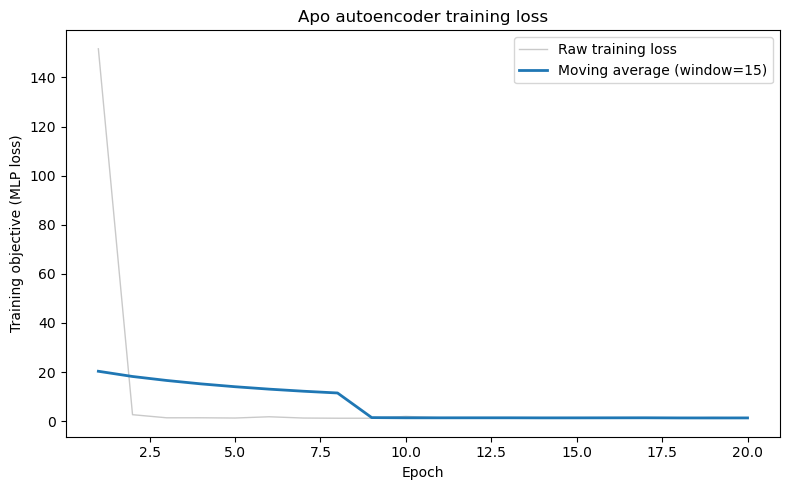

In [6]:
# Plot recorded training loss; smoothing changes only the visualization.
loss = np.asarray(reg.loss_curve_, dtype=float)
if loss.size == 0:
    raise ValueError("The model has no recorded training loss.")
if not isinstance(LOSS_SMOOTH_WINDOW, (int, np.integer)) or LOSS_SMOOTH_WINDOW < 1:
    raise ValueError("LOSS_SMOOTH_WINDOW must be a positive integer.")
window = min(LOSS_SMOOTH_WINDOW, loss.size)
epochs = np.arange(1, loss.size + 1)
# Centered moving average with shorter windows at the endpoints.
loss_smooth = pd.Series(loss).rolling(window, center=True, min_periods=1).mean().to_numpy()
pd.DataFrame({"epoch": epochs, "raw_loss": loss, "smoothed_loss": loss_smooth}).to_csv(
    OUTPUT_DIR / "allapo_training_loss.csv", index=False
)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(epochs, loss, color="0.65", alpha=0.6, linewidth=1, label="Raw training loss")
ax.plot(epochs, loss_smooth, color="tab:blue", linewidth=2,
        label=f"Moving average (window={window})")
ax.set(xlabel="Epoch", ylabel="Training objective (MLP loss)", title="Apo autoencoder training loss")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "allapo_training_loss_smooth.png", dpi=600, bbox_inches="tight")
plt.show()
plt.close(fig)


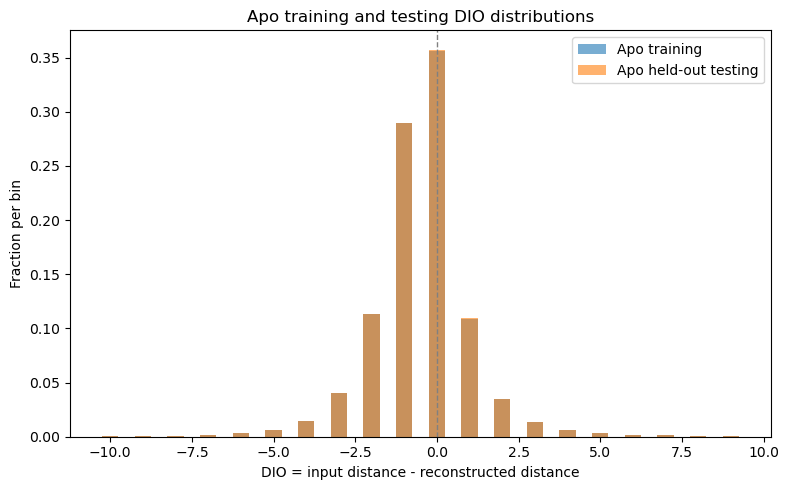

,system,subset,n_frames,n_features,mean_DIO,mean_abs_DIO,rmse,csv_file,histogram_file
0,allapo,training,4000,41616,-0.477879,1.109637,1.617331,autoencoder_outputs_new/dio_allapo_training.csv,autoencoder_outputs_new/allapo_training_dio.png
1,allapo,heldout_test,1000,41616,-0.477735,1.106405,1.612062,autoencoder_outputs_new/dio_allapo_heldout_tes...,autoencoder_outputs_new/allapo_heldout_test_di...


In [7]:
all_summaries = []
apo_histograms = {}

for subset_name, subset_data in (
    ("training", apo_train),
    ("heldout_test", apo_test),
):
    all_summaries.append(
        reconstruct_and_write(
            reg, subset_data, "allapo", subset_name,
            histogram_cache=apo_histograms,
        )
    )

bin_centers = (DIO_BINS[:-1] + DIO_BINS[1:]) / 2
bin_widths = np.diff(DIO_BINS)

fig, ax = plt.subplots(figsize=(8, 5))

for subset_name, label, color in (
    ("training", "Apo training", "tab:blue"),
    ("heldout_test", "Apo held-out testing", "tab:orange"),
):
    ax.bar(
        bin_centers,
        apo_histograms[subset_name],
        width=bin_widths * 0.5,
        color=color,
        alpha=0.6,
        label=label,
    )

ax.axvline(0, color="0.5", linestyle="--", linewidth=1)
ax.set(
    xlabel="DIO = input distance - reconstructed distance",
    ylabel="Fraction per bin",
    title="Apo training and testing DIO distributions",
)
ax.legend()
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "allapo_training_testing_dio.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

pd.DataFrame(all_summaries)